In [265]:
import pandas as pd
import matplotlib.pyplot as plt

In [266]:
df=pd.read_csv("student_performance (1).csv")

In [267]:
df.head()

,study_hours,exam_score
0,1.2,42
1,8.5,95
2,5.4,78
3,3.1,55
4,9.8,99


In [268]:
df.tail()

,study_hours,exam_score
634,5.7,84
635,0.3,37
636,8.7,100
637,3.4,67
638,7.9,99


In [269]:
df.shape

(639, 2)

In [270]:
df.isna().sum()

study_hours    0
exam_score     0
dtype: int64

In [271]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

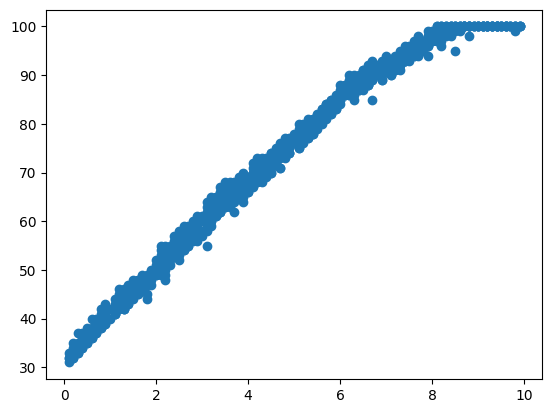

In [272]:
plt.scatter(x=x,y=y)

In [273]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.20,random_state=42)

In [274]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7.55]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['study_hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,36.36
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [275]:
y_pred=model.predict(x_test)
y_pred

array([103.5705846 ,  47.68594593, 108.10177152, 102.81538678,
       103.5705846 ,  95.26340858,  76.38346308,  89.22182602,
       106.59137588,  96.77380422,  58.25871541,  62.78990233,
        88.4666282 ,  45.42035247,  55.99312195,  96.0186064 ,
        84.6906391 ,  39.37876992,  75.62826527,  46.17555029,
        42.39956119, 104.32578242,  73.36267181, 102.81538678,
        42.39956119,  38.6235721 , 109.61216716,  99.03939768,
        99.03939768,  54.48272631,  71.09707835, 105.83617806,
        65.81069361,  76.38346308, 109.61216716,  47.68594593,
        77.1386609 ,  90.73222166, 105.83617806,  92.99781512,
        47.68594593, 110.36736497,  88.4666282 ,  89.97702384,
        45.42035247,  65.81069361,  93.75301294,  62.78990233,
        94.50821076,  61.27950669,  79.40425436,  82.42504564,
        83.18024346,  88.4666282 ,  71.85227617,  74.87306745,
       100.54979332,  91.48741948,  61.27950669,  69.58668271,
        65.05549579,  40.13396774, 111.12256279,  87.71

In [276]:
y_test

86     100
353     45
570    100
212    100
626    100
      ... 
425     92
244     92
248     60
369     59
430     70
Name: exam_score, Length: 128, dtype: int64

In [277]:
from sklearn.metrics import mean_absolute_error,r2_score,mean_absolute_percentage_error

In [278]:
print(mean_absolute_percentage_error(y_test,y_pred))

0.03890792844647893


In [279]:
print(mean_absolute_error(y_test,y_pred))

2.7186324239419015


In [280]:
print(r2_score(y_test,y_pred))

0.9714080960521853


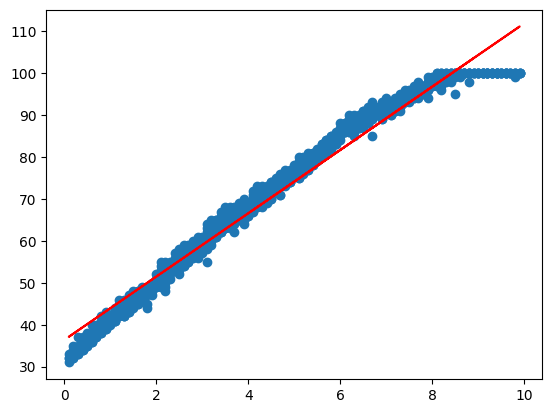

In [281]:
plt.scatter(x,y)
plt.plot(x_test,y_pred,color="r")

In [282]:
from sklearn.preprocessing import  PolynomialFeatures
poly=PolynomialFeatures(degree=2)
x_poly=poly.fit_transform(x_test)

In [283]:
x_poly

array([[1.000e+00, 8.900e+00, 7.921e+01],
       [1.000e+00, 1.500e+00, 2.250e+00],
       [1.000e+00, 9.500e+00, 9.025e+01],
       [1.000e+00, 8.800e+00, 7.744e+01],
       [1.000e+00, 8.900e+00, 7.921e+01],
       [1.000e+00, 7.800e+00, 6.084e+01],
       [1.000e+00, 5.300e+00, 2.809e+01],
       [1.000e+00, 7.000e+00, 4.900e+01],
       [1.000e+00, 9.300e+00, 8.649e+01],
       [1.000e+00, 8.000e+00, 6.400e+01],
       [1.000e+00, 2.900e+00, 8.410e+00],
       [1.000e+00, 3.500e+00, 1.225e+01],
       [1.000e+00, 6.900e+00, 4.761e+01],
       [1.000e+00, 1.200e+00, 1.440e+00],
       [1.000e+00, 2.600e+00, 6.760e+00],
       [1.000e+00, 7.900e+00, 6.241e+01],
       [1.000e+00, 6.400e+00, 4.096e+01],
       [1.000e+00, 4.000e-01, 1.600e-01],
       [1.000e+00, 5.200e+00, 2.704e+01],
       [1.000e+00, 1.300e+00, 1.690e+00],
       [1.000e+00, 8.000e-01, 6.400e-01],
       [1.000e+00, 9.000e+00, 8.100e+01],
       [1.000e+00, 4.900e+00, 2.401e+01],
       [1.000e+00, 8.800e+00, 7.74

In [284]:
x_poly.shape

(128, 3)

In [285]:
model1=LinearRegression()
model1.fit(x_poly,y_test)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. ,11.87,-0.44]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,28.81
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[340.79, 7.42, 0. ]"


In [286]:
y_pred1=model1.predict(x_poly)
y_pred1

array([ 99.73984544,  45.62759301, 102.02438836,  99.32842046,
        99.73984544,  94.73224755,  79.40833636,  90.42442812,
       101.297923  ,  95.72158003,  59.54518594,  64.98413437,
        89.84652062,  42.42181461,  56.70742151,  95.23129491,
        86.82554957,  33.48753376,  78.68147082,  43.49916965,
        38.02477209, 100.14250819,  76.44830079,  99.32842046,
        38.02477209,  32.33131859, 102.71580477,  97.13986197,
        97.13986197,  54.77176738,  74.13627062, 100.92154697,
        68.43485524,  79.40833636, 102.71580477,  45.62759301,
        80.12643965,  91.5539564 , 100.92154697,  93.18253205,
        45.62759301, 103.04836961,  89.84652062,  90.99357338,
        42.42181461,  68.43485524,  93.70786612,  64.98413437,
        94.22443795,  63.20620051,  82.22817612,  84.90782009,
        85.55582549,  89.84652062,  74.91570958,  77.94584305,
        98.04157208,  92.10557719,  63.20620051,  72.55110598,
        67.58531838,  34.6349867 , 103.37217222,  89.25

In [287]:
y_test

86     100
353     45
570    100
212    100
626    100
      ... 
425     92
244     92
248     60
369     59
430     70
Name: exam_score, Length: 128, dtype: int64

In [288]:
print(mean_absolute_percentage_error(y_test,y_pred1))

0.022479969407925557


In [289]:
print(mean_absolute_error(y_test,y_pred1))

1.5460916115192314


In [290]:
print(r2_score(y_test,y_pred1))

0.9924586388415929


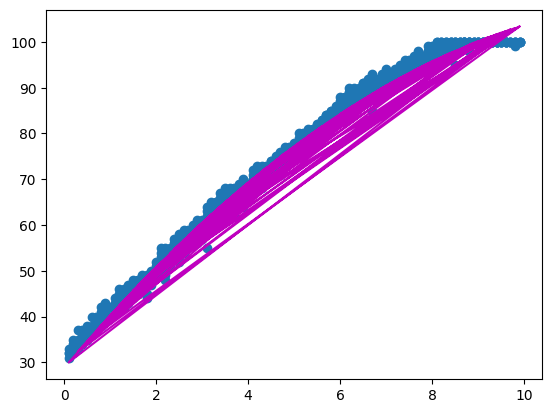

In [291]:
plt.scatter(x,y)
plt.plot(x_test,y_pred1,color="m")